
<div style="background-color:#dff2e1; padding:16px; border-radius:8px;">
<h1 style="margin-bottom:4px;">Industrial Data Analytics</h1>
<h2 style="margin-top:4px;">Practical Session 3 - Data Analytics Activities</h2>
</div>

### Connection to Lecture 3

Lecture 3 introduced the main activities in an industrial data analytics project:

1. Problem Definition
2. Data Collection
3. Model Selection
4. Model Development
5. Result Visualisation
6. Model Operation

The lecture also highlighted the importance of **preparation**, **understanding data sources**, and **initial data exploration**.

In this practical, you will follow these activities using sensor data from a simulated robotic arm.

> At the start of the session, compare your Practical 2 exercise with the separate worked-solution notebook from last week.



## Learning objectives

By the end of this practical you should be able to:

1. Define a simple engineering problem and identify useful Key Performance Indicators (KPIs).
2. Load and inspect a sensor dataset using pandas.
3. Identify and handle missing sensor values.
4. Calculate basic summary statistics to familiarise yourself with the data.
5. Explain why a particular analytics model might be selected.
6. Build a simple linear regression model as a demonstration of model development.
7. Visualise measured and modelled values.
8. Explain, at a basic level, how a model could be used operationally.

> **Important:** The model in this practical is a teaching demonstration. The dataset is very small and is not suitable for developing or validating a real predictive-maintenance model.



# Part 1 - Guided Practical



## 1. Problem Definition

### Engineering scenario

Assume that a robotic arm is being monitored because unexpected failures can interrupt an automated production line.

Three sensor variables are available:

- **Temperature** in °C
- **Vibration** in m/s²
- **Pressure** in kPa

For this teaching example, we will define simulated monitoring thresholds. These values are used only to demonstrate the analytics workflow and should not be treated as real equipment safety limits.


In [1]:
# Store the simulated temperature threshold in degrees Celsius.
temperature_threshold = 75.0

# Store the simulated vibration threshold in metres per second squared.
vibration_threshold = 10.0

# Store the simulated pressure threshold in kilopascals.
pressure_threshold = 150.0

# Display the simulated temperature threshold.
print("Temperature threshold:", temperature_threshold, "°C")

# Display the simulated vibration threshold.
print("Vibration threshold:", vibration_threshold, "m/s²")

# Display the simulated pressure threshold.
print("Pressure threshold:", pressure_threshold, "kPa")


Temperature threshold: 75.0 °C
Vibration threshold: 10.0 m/s²
Pressure threshold: 150.0 kPa



### Why are these variables useful?

The thresholds act as simple **KPIs or monitoring limits**. They help translate the engineering problem into measurable quantities that can be checked using sensor data.

A real project would define such limits using validated engineering requirements, equipment specifications, maintenance knowledge, standards, or experimental evidence.



## 2. Data Collection and Initial Exploration

The sensor readings have already been collected and saved in `robotic_arm_sensors.csv`.

Before analysing the data, we should inspect its structure and look for obvious problems.


In [2]:
# Import the pandas library for working with tabular data.
import pandas as pd

# Read the CSV file and store the table in a pandas DataFrame called data.
data = pd.read_csv("robotic_arm_sensors.csv")

# Display the first five rows so that we can visually inspect the imported data.
print(data.head())


   Time  Temperature  Vibration  Pressure
0     0         55.0        3.5     102.5
1     1         58.0        4.0       NaN
2     2          NaN        4.3       NaN
3     3          NaN        NaN       NaN
4     4         65.0        5.0     112.3


In [3]:
# Display the number of rows and columns in the dataset.
print("DataFrame shape:", data.shape)

# Display the names of the columns in the dataset.
print("Column names:", data.columns.tolist())

# Display the data type used by pandas for each column.
print("\nColumn data types:")
print(data.dtypes)


DataFrame shape: (5, 4)
Column names: ['Time', 'Temperature', 'Vibration', 'Pressure']

Column data types:
Time             int64
Temperature    float64
Vibration      float64
Pressure       float64
dtype: object


In [4]:
# Count the number of missing values in each column.
missing_values = data.isnull().sum()

# Display the number of missing values found in each column.
print("Missing values in each column:")
print(missing_values)


Missing values in each column:
Time           0
Temperature    2
Vibration      1
Pressure       3
dtype: int64



### Initial observations

The dataset contains only a few rows because it is designed for teaching. You should notice that some values are missing.

In industrial projects, missing values may occur because of:

- communication faults;
- sensor dropouts;
- maintenance periods;
- data logging errors;
- temporary sensor failures.

Before model development, these issues must be investigated and handled appropriately.



## 3. Data Preprocessing

To preserve the original data, we will first create a copy.

For this guided example, missing values will be replaced by the **mean of the available values in the same column**. This is a simple teaching method. In real industrial work, the correct treatment depends on why the data is missing and on the physical process.


In [5]:
# Create a copy of the original dataset so that the raw data remains unchanged.
data_clean = data.copy()

# Calculate the mean of the available temperature measurements.
temperature_mean = data_clean["Temperature"].mean()

# Calculate the mean of the available vibration measurements.
vibration_mean = data_clean["Vibration"].mean()

# Calculate the mean of the available pressure measurements.
pressure_mean = data_clean["Pressure"].mean()

# Display the temperature mean that will be used to replace missing temperature values.
print(f"Temperature mean used for filling: {temperature_mean:.2f} °C")

# Display the vibration mean that will be used to replace missing vibration values.
print(f"Vibration mean used for filling: {vibration_mean:.2f} m/s²")

# Display the pressure mean that will be used to replace missing pressure values.
print(f"Pressure mean used for filling: {pressure_mean:.2f} kPa")


Temperature mean used for filling: 59.33 °C
Vibration mean used for filling: 4.20 m/s²
Pressure mean used for filling: 107.40 kPa


In [6]:
# Replace missing temperature values with the calculated temperature mean.
data_clean["Temperature"] = data_clean["Temperature"].fillna(temperature_mean)

# Replace missing vibration values with the calculated vibration mean.
data_clean["Vibration"] = data_clean["Vibration"].fillna(vibration_mean)

# Replace missing pressure values with the calculated pressure mean.
data_clean["Pressure"] = data_clean["Pressure"].fillna(pressure_mean)

# Display the cleaned dataset.
print(data_clean)


   Time  Temperature  Vibration  Pressure
0     0    55.000000        3.5     102.5
1     1    58.000000        4.0     107.4
2     2    59.333333        4.3     107.4
3     3    59.333333        4.2     107.4
4     4    65.000000        5.0     112.3


In [7]:
# Count missing values again after cleaning.
missing_values_after_cleaning = data_clean.isnull().sum()

# Display the new missing-value counts so that we can verify the cleaning step.
print("Missing values after cleaning:")
print(missing_values_after_cleaning)


Missing values after cleaning:
Time           0
Temperature    0
Vibration      0
Pressure       0
dtype: int64



### Why make a copy?

Keeping the original dataset unchanged is good practice. It allows you to compare the raw and cleaned data and makes it easier to identify what preprocessing has been performed.



## 4. Data Familiarisation Using Summary Statistics

Lecture 3 emphasised initial exploration before detailed analysis. Summary statistics help us understand the typical values, variation, and range of the sensor measurements.


In [8]:
# Calculate a standard statistical summary for every numeric column.
summary_statistics = data_clean.describe()

# Display the statistical summary table.
print(summary_statistics)


           Time  Temperature  Vibration    Pressure
count  5.000000     5.000000   5.000000    5.000000
mean   2.000000    59.333333   4.200000  107.400000
std    1.581139     3.628590   0.543139    3.464823
min    0.000000    55.000000   3.500000  102.500000
25%    1.000000    58.000000   4.000000  107.400000
50%    2.000000    59.333333   4.200000  107.400000
75%    3.000000    59.333333   4.300000  107.400000
max    4.000000    65.000000   5.000000  112.300000


In [9]:
# Calculate the mean temperature after cleaning.
mean_temperature = data_clean["Temperature"].mean()

# Calculate the median temperature after cleaning.
median_temperature = data_clean["Temperature"].median()

# Calculate the standard deviation of temperature after cleaning.
std_temperature = data_clean["Temperature"].std()

# Display the mean temperature.
print(f"Mean temperature: {mean_temperature:.2f} °C")

# Display the median temperature.
print(f"Median temperature: {median_temperature:.2f} °C")

# Display the temperature standard deviation.
print(f"Temperature standard deviation: {std_temperature:.2f} °C")


Mean temperature: 59.33 °C
Median temperature: 59.33 °C
Temperature standard deviation: 3.63 °C



### Interpretation

Summary statistics do not explain everything about the system, but they help us become familiar with the dataset before selecting or building a model.



## 5. Model Selection

Suppose our simple question is:

**Can we describe the trend of temperature with elapsed time?**

A **linear regression** model is a reasonable teaching choice because:

- the target variable, temperature, is numerical;
- the input variable, time, is numerical;
- the model is easy to visualise and interpret.

This does **not** mean linear regression is automatically the best model for real robotic-arm failure prediction. Real model selection depends on the engineering problem, the available data, and model-validation results.



## 6. Model Development - Linear Regression Demonstration

We will fit a simple line relating temperature to time.

Because this dataset contains only five rows, we will use all rows for the demonstration rather than pretending that such a small dataset provides a meaningful training/testing evaluation.


In [10]:
# Import the LinearRegression model from scikit-learn.
from sklearn.linear_model import LinearRegression

# Select the Time column as the input feature and keep it as a DataFrame.
X_temperature = data_clean[["Time"]]

# Select the Temperature column as the target variable.
y_temperature = data_clean["Temperature"]

# Create a new linear regression model.
temperature_model = LinearRegression()

# Fit the model using time as the input and temperature as the target.
temperature_model.fit(X_temperature, y_temperature)

# Use the fitted model to calculate a modelled temperature for every recorded time.
predicted_temperature = temperature_model.predict(X_temperature)


In [11]:
# Create a table containing time, measured temperature, and modelled temperature.
temperature_comparison = pd.DataFrame({
    "Time": data_clean["Time"],
    "Actual Temperature": y_temperature,
    "Modelled Temperature": predicted_temperature
})

# Display the comparison table.
print(temperature_comparison)


   Time  Actual Temperature  Modelled Temperature
0     0           55.000000             55.066667
1     1           58.000000             57.200000
2     2           59.333333             59.333333
3     3           59.333333             61.466667
4     4           65.000000             63.600000


In [12]:
# Display the slope of the fitted regression line.
print(f"Model slope: {temperature_model.coef_[0]:.3f} °C per second")

# Display the intercept of the fitted regression line.
print(f"Model intercept: {temperature_model.intercept_:.3f} °C")


Model slope: 2.133 °C per second
Model intercept: 55.067 °C



### What do slope and intercept mean?

The **slope** describes the change in modelled temperature for a one-second increase in time.

The **intercept** is the temperature predicted by the fitted line when time equals zero.

At this stage, the purpose is to understand the workflow rather than to judge the quality of the model.



## 7. Result Visualisation

We can now compare the measured temperature values with the fitted regression line.


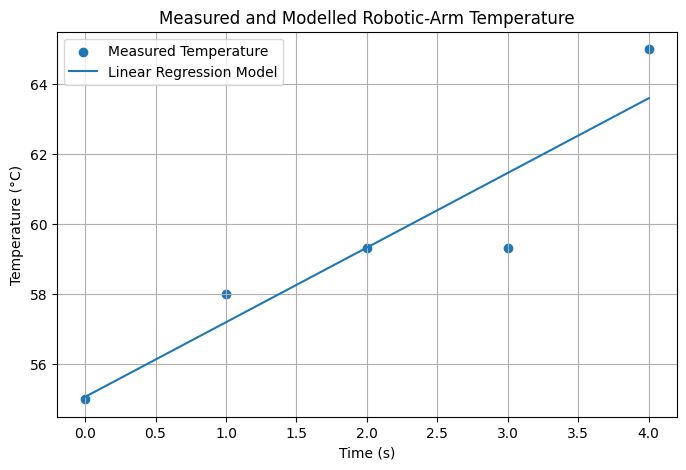

In [13]:
# Import the pyplot section of Matplotlib for creating graphs.
import matplotlib.pyplot as plt

# Create a new figure with a suitable size.
plt.figure(figsize=(8, 5))

# Plot the measured temperature values as points.
plt.scatter(data_clean["Time"], data_clean["Temperature"], label="Measured Temperature")

# Plot the modelled temperature values as a line.
plt.plot(data_clean["Time"], predicted_temperature, label="Linear Regression Model")

# Label the horizontal axis and include its unit.
plt.xlabel("Time (s)")

# Label the vertical axis and include its unit.
plt.ylabel("Temperature (°C)")

# Add a meaningful graph title.
plt.title("Measured and Modelled Robotic-Arm Temperature")

# Display a legend so the two plotted datasets can be identified.
plt.legend()

# Add grid lines to make the graph easier to read.
plt.grid(True)

# Display the graph.
plt.show()



### Interpreting the visualisation

The plotted line gives a simplified representation of the temperature trend. Differences between the points and the line show that the model does not reproduce every measurement exactly.

This is one reason why model validation is important in real projects.



## 8. Model Operation - Simple Demonstration

Lecture 3 also introduced model operation. A deployed model would receive new operational data and generate an output that could support a decision.

Here we will simply demonstrate how the fitted model can be given a new time value.


In [14]:
# Create a one-row DataFrame representing a new time value of 5 seconds.
new_time = pd.DataFrame({"Time": [5]})

# Ask the fitted model to estimate the temperature at the new time.
predicted_future_temperature = temperature_model.predict(new_time)

# Display the model output for the new time value.
print(f"Modelled temperature at 5 s: {predicted_future_temperature[0]:.2f} °C")


Modelled temperature at 5 s: 65.73 °C



> **Important:** This is only a demonstration of how a trained model can be used. A real deployed predictive-maintenance model would require far more data, proper validation, continuous monitoring, and engineering controls.



## 9. Connecting the Practical to the Analytics Activities

| Analytics activity | What we did in this practical |
|---|---|
| **Problem Definition** | Defined a robotic-arm monitoring problem and simulated KPI thresholds. |
| **Data Collection** | Loaded previously collected sensor data from a CSV file. |
| **Preparation / Exploration** | Inspected columns, data types, missing values, and summary statistics. |
| **Model Selection** | Chose linear regression as a simple model for temperature versus time. |
| **Model Development** | Fitted the linear regression model. |
| **Result Visualisation** | Compared measured temperature with the modelled trend. |
| **Model Operation** | Supplied a new time value to the fitted model to generate an output. |



# Part 2 - Student Exercise

## Robotic-arm data preparation and monitoring task

You will now repeat the analytics workflow independently using the same raw dataset, but with different decisions and a different sensor variable.

For this exercise, use the following **simulated alert thresholds**:

- Temperature: **60 °C**
- Vibration: **4.5 m/s²**
- Pressure: **110 kPa**

These are exercise values only and are not real safety limits.



### Task 1 - Define the problem and KPIs

1. Create three Python variables containing the exercise thresholds.
2. Print the three thresholds with their units.
3. In one or two sentences, explain what engineering question these thresholds help us answer.

**Hint:** Follow the pattern used in Part 1.


In [15]:
# Write your code for Task 1 below.




**Write your engineering question here:**

-



### Task 2 - Load and inspect the raw data

1. Load `robotic_arm_sensors.csv` into a new DataFrame called `exercise_data`.
2. Display the first five rows.
3. Display the shape of the DataFrame.
4. Display the data types.
5. Count the missing values in each column.

**Hint:** Use `pd.read_csv()`, `.head()`, `.shape`, `.dtypes`, and `.isnull().sum()`.


In [16]:
# Write your code for Task 2 below.




### Task 3 - Clean the missing values

For this exercise, replace missing values using the **median** of each sensor column rather than the mean.

1. Create a copy called `exercise_clean`.
2. Calculate the median of Temperature, Vibration, and Pressure.
3. Fill the missing values in each sensor column with its median.
4. Verify that no missing values remain.

**Hint:** The syntax is similar to `.mean()`, but use `.median()` instead.


In [17]:
# Write your code for Task 3 below.




### Task 4 - Explore the cleaned data

Calculate and display:

1. mean Temperature;
2. maximum Temperature;
3. mean Vibration;
4. maximum Vibration;
5. mean Pressure;
6. maximum Pressure.

Then identify which sensor reaches the largest proportion of its exercise threshold.

**Hint:** Compare each maximum value with its corresponding threshold.


In [18]:
# Write your code for Task 4 below.




**Which sensor reaches the largest proportion of its exercise threshold, and how do you know?**

-



### Task 5 - Apply the monitoring rules

Use the **maximum value** of each sensor and `if` statements to report whether each exercise threshold was exceeded.

Your output should clearly state the condition for:

- Temperature
- Vibration
- Pressure

**Hint:** Calculate each maximum first, then compare it with the appropriate threshold.


In [19]:
# Write your code for Task 5 below.




### Task 6 - Visualise the data

Create two separate graphs:

1. Temperature against Time
2. Vibration against Time

Each graph should contain:

- markers;
- axis labels with units;
- a meaningful title;
- grid lines.

**Hint:** Use the plotting code from Part 1 as a pattern.


In [20]:
# Write your code for Task 6 below.




### Task 7 - Model Selection and Development

Assume you want to describe the trend of **Vibration with Time**.

1. Use `Time` as the input feature.
2. Use `Vibration` as the target.
3. Create and fit a `LinearRegression` model.
4. Calculate modelled vibration values for all recorded times.
5. Create a comparison table containing:
   - Time
   - Actual Vibration
   - Modelled Vibration

**Hint:** Adapt the temperature model from Part 1 by changing the target variable.


In [21]:
# Write your code for Task 7 below.




### Task 8 - Interpret the workflow

Answer the following questions in your own words.

1. Why did we inspect missing values before model development?
2. Why might median filling give a different result from mean filling?
3. Why is a five-row dataset not enough to validate a real predictive model?
4. Which analytics activity does the comparison graph belong to?
5. What additional evidence would you want before deploying this model on a real robotic arm?

**Write your answers here:**

1.  
2.  
3.  
4.  
5.  



## Optional challenge - Create an alert column

Create a new Boolean column called `Alert`.

The value should be `True` if **any** of the following conditions are true for a row:

- Temperature > 60 °C
- Vibration > 4.5 m/s²
- Pressure > 110 kPa

Otherwise, the value should be `False`.

Then display the cleaned DataFrame including the new column.

**Hint:** Conditions can be combined using the `|` symbol, which means OR.


In [22]:
# Write your optional challenge code below.




# End-of-practical reflection

Before finishing, check that you can explain:

- why problem definition comes before model development;
- why data quality matters;
- why we inspect data before choosing a model;
- the difference between model selection and model development;
- why visualisation is part of communicating analytical results;
- why a model must be validated before real operational use.

### Save your work

Save your completed notebook. A worked solution to Part 2 will be provided for comparison.
